In [1]:
import time
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.appName("phase2-eda").getOrCreate()
plt.rcParams["figure.figsize"] = (10, 4)
SHOTS = "/home/jovyan/work/reports/screenshots"

In [2]:
t0 = time.time()
tx = spark.read.parquet("/home/jovyan/work/data/processed/train_transaction")
print(f"loaded {tx.count():,} rows in {time.time()-t0:.1f}s")

loaded 590,540 rows in 11.8s


In [3]:
total = tx.count()
fraud = tx.filter(F.col("isFraud") == 1).count()
rate  = fraud / total * 100
print(f"legitimate: {total-fraud:,}   |   fraud: {fraud:,}   |   fraud rate: {rate:.2f}%")

legitimate: 569,877   |   fraud: 20,663   |   fraud rate: 3.50%


             n  fraud  fraud_rate
band                             
0-1        152     22       14.47
1-10      6643    544        8.19
10-100  341462  11532        3.38
100-1k  234703   8378        3.57
1k+       7580    187        2.47


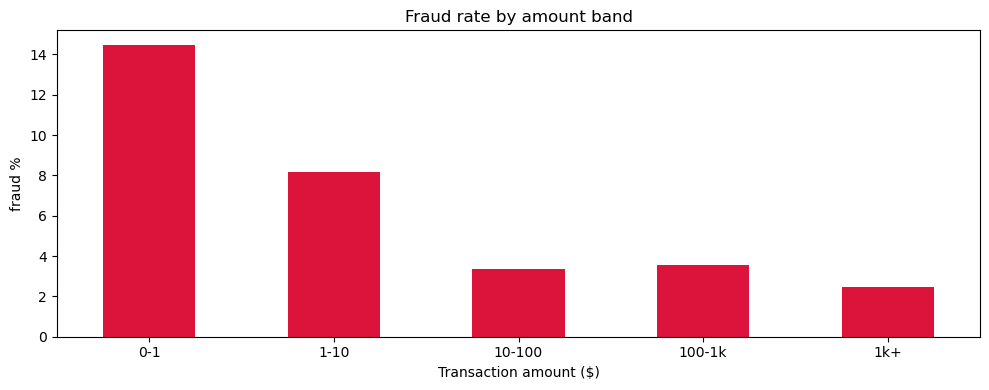

In [4]:
bands = F.when(F.col("TransactionAmt") < 1, "0-1") \
    .when(F.col("TransactionAmt") < 10, "1-10") \
    .when(F.col("TransactionAmt") < 100, "10-100") \
    .when(F.col("TransactionAmt") < 1000, "100-1k") \
    .otherwise("1k+")

eda_amt = (tx.withColumn("band", bands)
    .groupBy("band")
    .agg(F.count("*").alias("n"),
         F.sum("isFraud").alias("fraud"))
    .withColumn("fraud_rate", F.round(F.col("fraud")/F.col("n")*100, 2))
    .toPandas()
    .set_index("band").reindex(["0-1", "1-10", "10-100", "100-1k", "1k+"]))

print(eda_amt)
ax = eda_amt["fraud_rate"].plot.bar(rot=0, color="crimson")
ax.set_xlabel("Transaction amount ($)"); ax.set_ylabel("fraud %")
ax.set_title("Fraud rate by amount band")
plt.tight_layout(); plt.savefig(f"{SHOTS}/06_eda_amount_bands.png", dpi=150); plt.show()

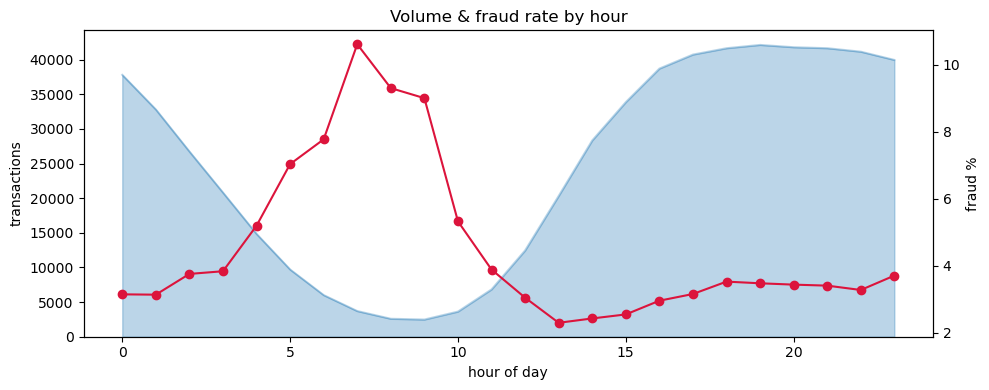

In [5]:
eda_hr = (tx.withColumn("hour", F.floor((F.col("TransactionDT") % 86400) / 3600))
    .groupBy("hour")
    .agg(F.count("*").alias("n"), F.sum("isFraud").alias("fraud"))
    .withColumn("fraud_rate", F.round(F.col("fraud")/F.col("n")*100, 2))
    .toPandas().sort_values("hour"))

ax = eda_hr.plot.area(x="hour", y="n", alpha=0.3, legend=False)
ax2 = ax.twinx()
ax2.plot(eda_hr["hour"], eda_hr["fraud_rate"], color="crimson", marker="o")
ax.set_xlabel("hour of day"); ax.set_ylabel("transactions"); ax2.set_ylabel("fraud %")
ax.set_title("Volume & fraud rate by hour")
plt.tight_layout(); plt.savefig(f"{SHOTS}/07_eda_hourly_pattern.png", dpi=150); plt.show()

columns total: 394
columns >80% missing: 55  (Phase-2 drop candidates)
columns >95% missing: 0


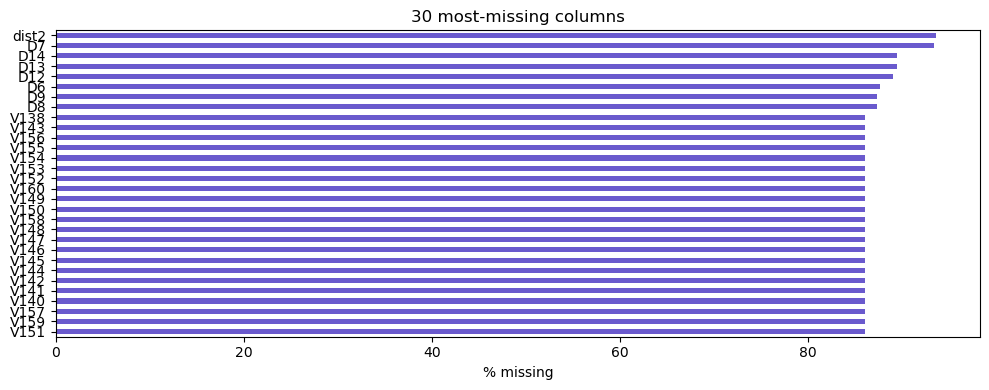

In [6]:
cols = tx.columns
census = (tx.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in cols])
    .toPandas().T.rename(columns={0: "missing"}))
census["missing_%"] = (census["missing"] / total * 100).round(1)
census = census.sort_values("missing_%", ascending=False)

print(f"columns total: {len(cols)}")
print(f"columns >80% missing: {(census['missing_%'] > 80).sum()}  (Phase-2 drop candidates)")
print(f"columns >95% missing: {(census['missing_%'] > 95).sum()}")

top = census.head(30).sort_values("missing_%")
ax = top["missing_%"].plot.barh(color="slateblue")
ax.set_xlabel("% missing"); ax.set_title("30 most-missing columns")
plt.tight_layout(); plt.savefig(f"{SHOTS}/08_eda_missing_census.png", dpi=150); plt.show()